
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



In [ ]:
from sklearn.datasets import load_digits
from random import randint

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import BboxImage
from matplotlib.transforms import Bbox, TransformedBbox
import pandas as pd
%matplotlib inline

# <font color="blue"> Proceso </font>

Podemos resumir el proceso a seguir para **reducir la dimensionalidad** de un conjunto de datos, usando **PCA**, en la siguiente lista de pasos:

1. Evaluar la matriz de covarianza de los datos.
2. Calcular los valores y vectores propios de la matriz de covarianza.
3. Identificar el total de componentes principales que deben considerarse para la proyección de los datos preservando un mínimo de información de la matriz de covarianza (generalmente del 70 al 80%).
4. Construir la matriz de proyección ubicando en sus columnas a los vectores propios (seleccionados en el punto anterior).
5. Proyectamos los datos multiplicando por la matriz de proyección, reduciendo de forma efectiva su dimensionalidad.

Revisemos algunos ejemplos.



# <font color="blue"> Calificaciones en examen de admisión</font>

In [ ]:
dat = pd.read_csv("examen_data.csv")
dat.head()

,mat,fis,esp,lec
0,987.293813,979.823870,1018.481276,1023.073783
1,986.302222,1001.704575,982.546053,984.426305
2,971.015410,972.496385,1035.605273,1031.472877
3,1031.318324,1015.896592,1005.115753,1002.394719
4,1002.335095,1031.289476,1011.179274,1018.275839


### Matriz de covarianza

In [ ]:
X = dat.values #accede a la matriz de datos

xm = np.mean(X, axis = 0) #medias de las variables

C = np.dot(np.transpose(X-xm), X-xm)/(len(X)-1)
C #matriz de 4x4

array([[842.41615643, 630.35592768,  77.17269571, 128.47466242],
       [630.35592768, 875.31416348,  94.59273229,  73.87015651],
       [ 77.17269571,  94.59273229, 874.99284214, 679.85433985],
       [128.47466242,  73.87015651, 679.85433985, 804.37891197]])

### Valores y vectores propios

In [ ]:
l, v = np.linalg.eig(C)
print(l)
print("#####")
print(v)

[1692.21121923 1318.29134455  243.84794333  142.75156692]
#####
[[ 0.4798601   0.5047958   0.65465747 -0.29383512]
 [ 0.47775798  0.53543249 -0.64363792  0.26606311]
 [ 0.52746336 -0.49930473 -0.28281531 -0.62649237]
 [ 0.51309259 -0.45737078  0.27779366  0.67110256]]


### Total de componentes principales

En esta celda decidimos el total de componentes principales que debemos seleccionar para proyectar nuestros datos, esto es, decidimos la dimensión del nuevo espacio:

In [ ]:
var_tot = sum(l)
np.cumsum(l)/var_tot*100 #total de varianza acumulada

array([ 49.81337571,  88.61972641,  95.79784287, 100.        ])

Observa que es suficiente con utilizar las dos componentes principales para que la proyección preserve casi el 90% de la información del conjunto de datos original.

### Matriz de proyección

La matriz de proyección estará compuesta por dos columnas, cada una de las cuales corresponde a un vector principal:


In [ ]:
A = v[:,:2] #seleccionamos los dos primeros vectores principales
A #matriz de 4 x 2

array([[ 0.4798601 ,  0.5047958 ],
       [ 0.47775798,  0.53543249],
       [ 0.52746336, -0.49930473],
       [ 0.51309259, -0.45737078]])

### Proyección

La proyección la realizamos multiplicando la matriz de datos por la de proyección:

In [ ]:
Xp = np.dot(X, A)
Xp.shape

(1000, 2)

In [ ]:
#los datos originales tienen una dimensionalidad de 4
X.shape

(1000, 4)

In [ ]:
# revisamos la proyección de las primeras observaciones
Xp[:10,:]

array([[2004.02470857,   46.55473807],
       [1975.2183169 ,   93.38868158],
       [2006.05438216,   22.02250234],
       [2024.72424717,  104.22410231],
       [2029.51719539,   87.54423524],
       [1959.23165143,  116.04608162],
       [1958.33567396,   52.62863473],
       [1987.54301512,   88.35556571],
       [1958.15847831,  116.92836102],
       [1995.6717723 ,   67.36397412]])

In [ ]:
X[0,]

array([ 987.2938132,  979.82387  , 1018.481276 , 1023.073783 ])



**Con ```sklearn```:**

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca = PCA(n_components=4) # usamos todas las dimensiones inicialmente para identificar el total de varianza proyectada
pca_examen = pca.fit(X)

Varianza explicada por cada componente

In [ ]:
pca_examen.explained_variance_

array([1692.21121923, 1318.29134455,  243.84794333,  142.75156692])

**En porcentaje**



In [ ]:
np.cumsum(pca_examen.explained_variance_ratio_*100)

array([ 49.81337571,  88.61972641,  95.79784287, 100.        ])

Proyectamos a dos componentes

In [ ]:
pca = PCA(n_components=2) # usamos todas las dimensiones inicialmente para identificar el total de varianza proyectada
pca.fit(X)

PCA(n_components=2)

In [ ]:
pca.transform(X)

array([[  6.12616114, -37.79539654],
       [-22.68023053,   9.03854698],
       [  8.15583473, -62.32763227],
       ...,
       [-19.2193176 ,  17.50724815],
       [-22.86540534,   3.80916517],
       [ 67.5486369 ,  95.39236148]])

# <font color="blue"> Calidad de vida [ejemplo]</font>

Fuente de los datos: https://www.kaggle.com/datasets/dumbgeek/countries-dataset-2020?select=Quality+of+life+index+by+countries+2020.csv

In [ ]:
dat = pd.read_csv("quality_life_2020.csv")
dat.head()

,Country,Índice de calidad de vida,Índice de poder adquisitivo,Índice de seguridad,Índice de atención de salud,Índice del costo de vida,Relación precio de la propiedad/ingresos,Índice de tiempo de viaje en función del tráfico,Índice de contaminación,Índice climático
0,Denmark,192.67,100.88,74.90,80.00,83.00,7.45,28.85,21.33,81.80
1,Switzerland,192.01,119.53,78.40,72.44,122.40,8.68,29.09,22.39,79.24
2,Finland,190.22,99.93,76.68,75.79,70.29,8.35,29.90,11.55,58.87
3,Australia,186.21,107.31,58.64,77.38,73.54,7.52,34.73,23.46,92.70
4,Netherlands,183.67,90.73,72.38,74.65,73.75,7.51,29.43,27.41,87.61


In [ ]:
dat = pd.read_csv("communities.data")
dat.head()

,8,?,?.1,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,...,0.12.2,0.26.1,0.2.1,0.06.3,0.04.2,0.9.1,0.5.2,0.32.2,0.14.3,0.2.2
0,53,?,?,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,?,?,?,?,0.0,?,0.67
1,24,?,?,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,?,?,?,?,0.0,?,0.43
2,34,5,81440,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,?,?,?,?,0.0,?,0.12
3,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,?,?,?,?,0.0,?,0.03
4,6,?,?,SouthPasadenacity,1,0.02,0.28,0.06,0.54,1.00,...,0.01,0.58,0.10,?,?,?,?,0.0,?,0.14


**Problemas con escalas**

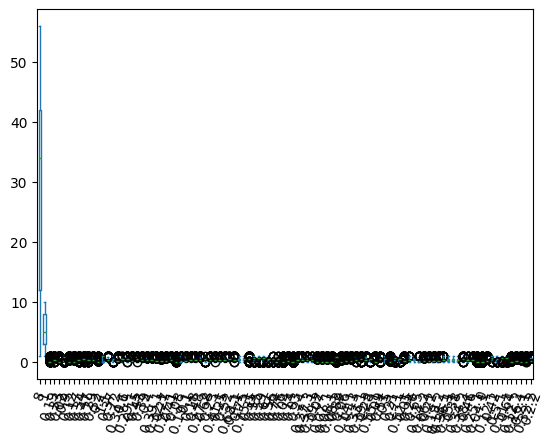

In [ ]:
import matplotlib.pyplot as plt

dat.plot.box()
plt.xticks(rotation=45)
plt.show()


Estandarizamos las variables para evitar una influencia excesiva debida a la escala.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = dat.drop("Country", axis=1) #solo variables numéricas
scaler.fit(X)
Xs = scaler.transform(X)

KeyError: "['Country'] not found in axis"

Las variables tienen ahora escalas similares:

<Axes: >

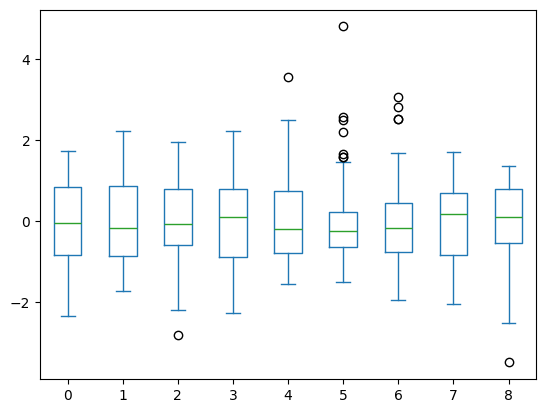

In [ ]:
pd.DataFrame(Xs).plot.box()

Aplicamos la descomposición en componentes principales.

In [ ]:
pca = PCA(n_components = 9)
pca_countries = pca.fit(Xs)

Varianza explicada

In [ ]:
porc_exp_var = np.round(pca_countries.explained_variance_ratio_*100,2)
porc_exp_var

array([53.01, 13.62, 12.05,  8.46,  4.7 ,  3.75,  2.77,  1.65,  0.  ])

Varianza acumulada

In [ ]:
np.cumsum(porc_exp_var)

array([ 53.01,  66.63,  78.68,  87.14,  91.84,  95.59,  98.36, 100.01,
       100.01])

Proyectamos los datos a 3 dimensiones.

In [ ]:
pca = PCA(n_components = 3)
pca_countries3 = pca.fit_transform(Xs)
pca_countries3

array([[ 3.81592409e+00,  6.73164241e-01,  2.51879502e-03],
       [ 4.60021630e+00,  8.08150482e-01,  4.31465942e-01],
       [ 3.60456592e+00, -5.15085372e-01,  6.26919421e-01],
       [ 2.91513209e+00,  1.31348200e+00, -8.05124531e-01],
       [ 3.00170979e+00,  5.70807478e-01, -4.30166907e-01],
       [ 3.14373439e+00,  3.24444038e-01,  2.70697209e-01],
       [ 3.79435806e+00, -6.03729163e-01, -1.41380996e-01],
       [ 2.62064303e+00,  1.16649368e+00, -1.02531596e+00],
       [ 2.62600060e+00,  4.69913722e-01, -3.56675469e-01],
       [ 2.58803405e+00, -9.09727298e-01,  1.65401408e-01],
       [ 2.51622214e+00,  1.90166949e-01, -6.19300040e-01],
       [ 3.41698414e+00,  4.04633967e-01,  6.60897244e-02],
       [ 2.01335291e+00, -5.66925495e-01, -2.02687889e-01],
       [ 2.32742000e+00,  3.24928170e-02, -9.85847332e-01],
       [ 1.89625164e+00,  8.33866148e-01, -5.77178400e-01],
       [ 2.44877603e+00,  1.36285409e+00,  9.61938670e-01],
       [ 1.89543386e+00, -1.63076559e+00

Observa lo siguiente:

1. Hemos transformado los datos aplicado la composición de dos transformaciones:
  * Estandarización.
  * Proyección a las 3 primeras componenets principales.
2. Las transformaciones redujeron la dimensionalidad de 9 a 3.




# <font color="blue">Práctica</font>

Aplica la técnica de análisis de componentes principales al conjunto de datos disponible en el siguiente enlace:

https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime

* Carga los datos e ignora las variables ```state```, ```county```, ```community```, ```fold``` [todas ellas son categóricas aunque algunas se representen numéricamente]. Ignora cualquier otra variable categórica que encuentres.  
* Explora los datos y verifica si las escalas de las variables son similares, en caso contrario, estandariza.
* Aplica la técnica de PCA sobre los datos, proyectando a un número de dimensiones tal que se preserve, por lo menos, el $70\%$ de la varianza original.



# <font color="blue"> CODIGO DE PRÁCTICA[ejemplo]</font>

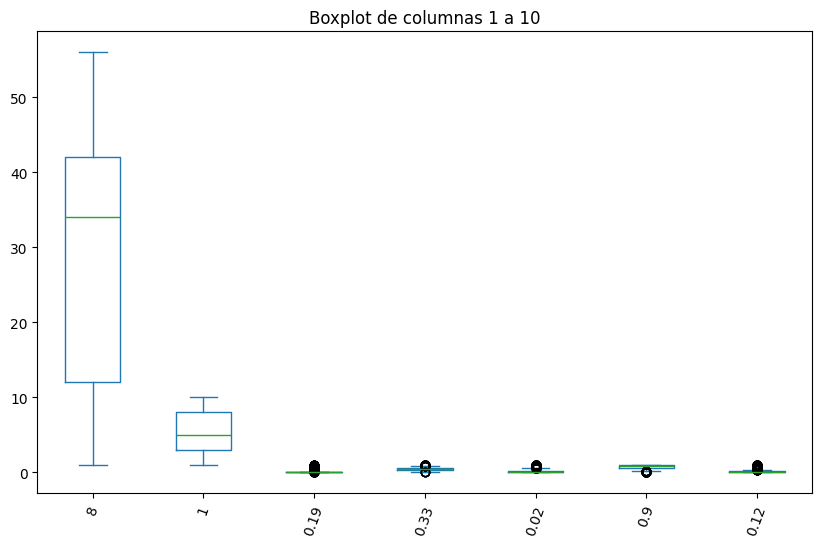

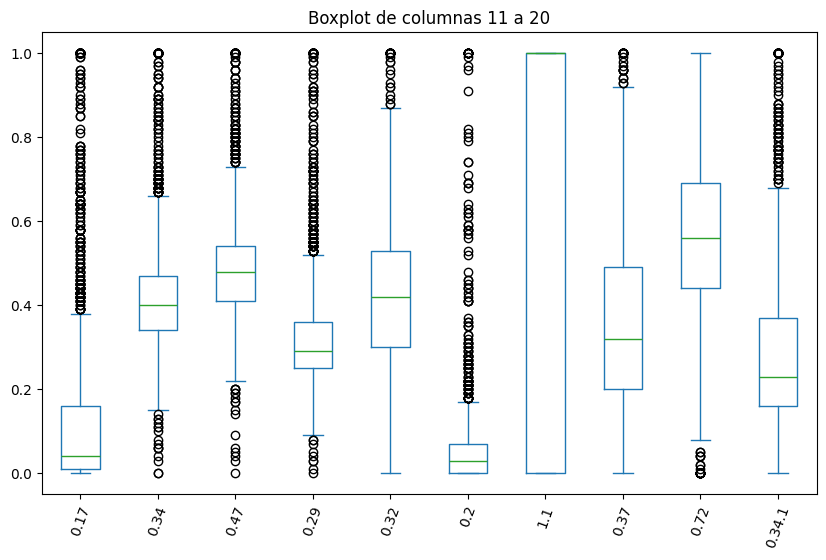

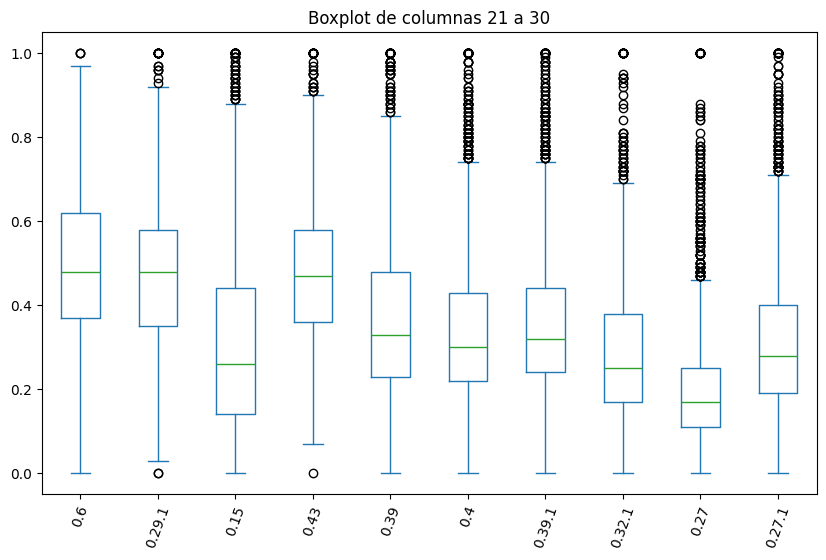

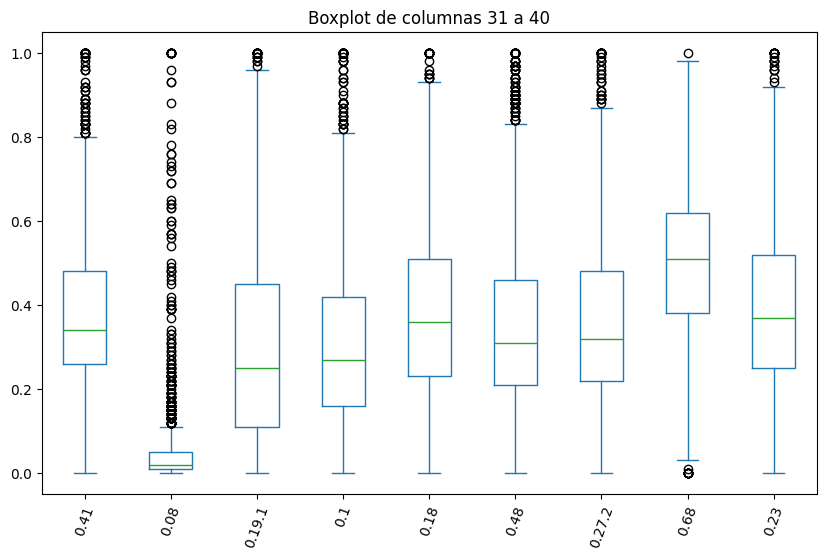

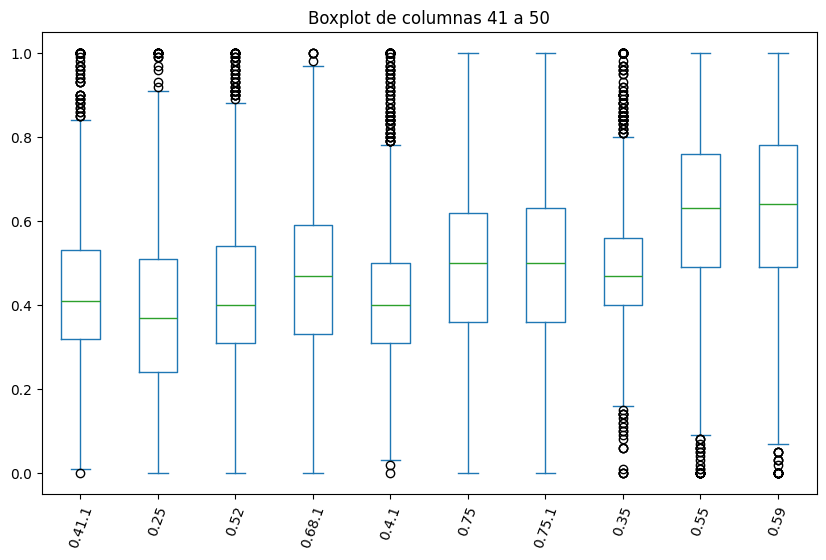

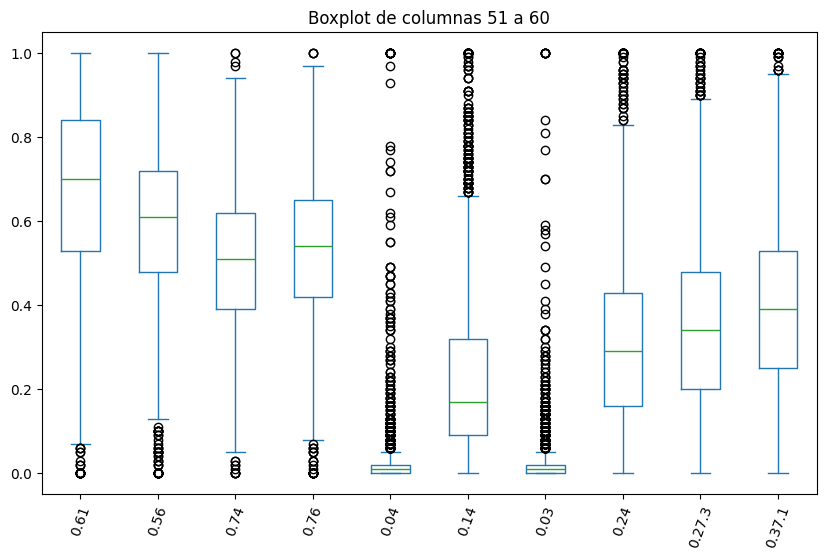

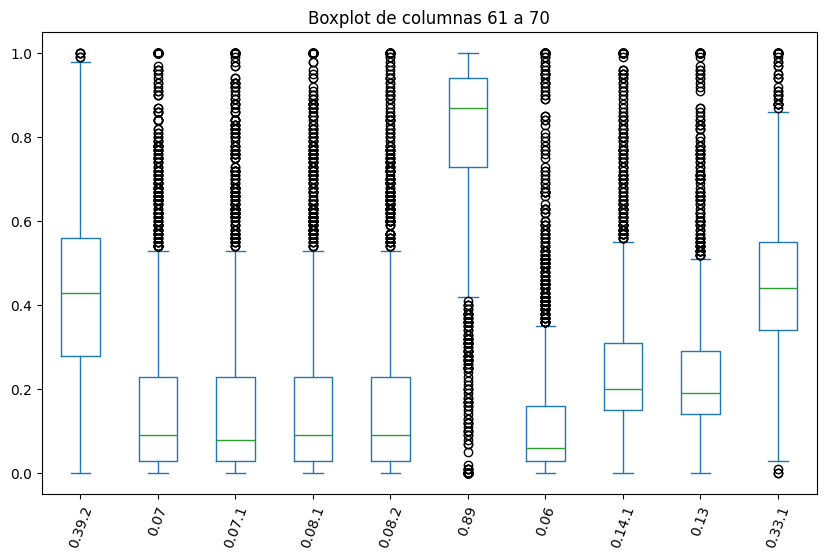

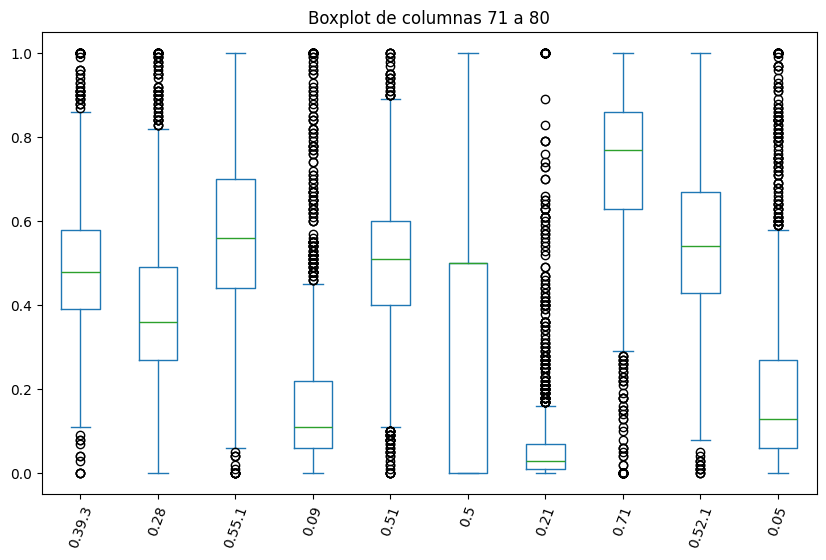

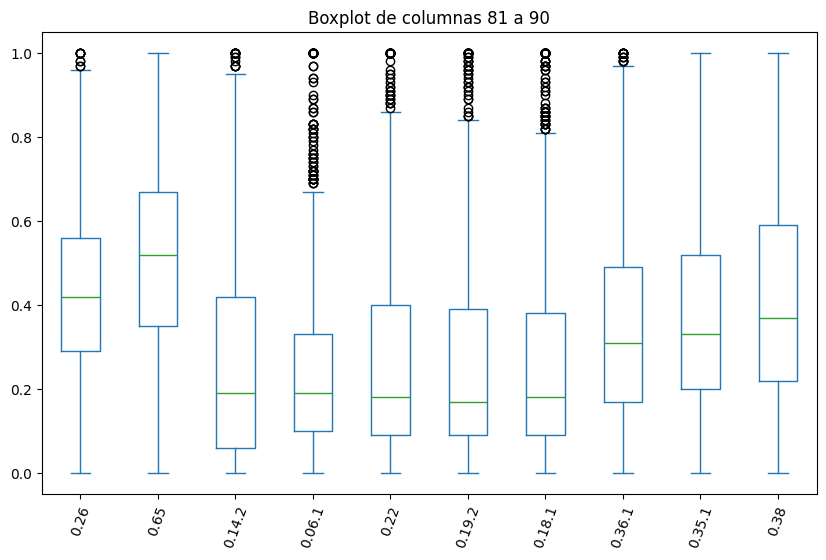

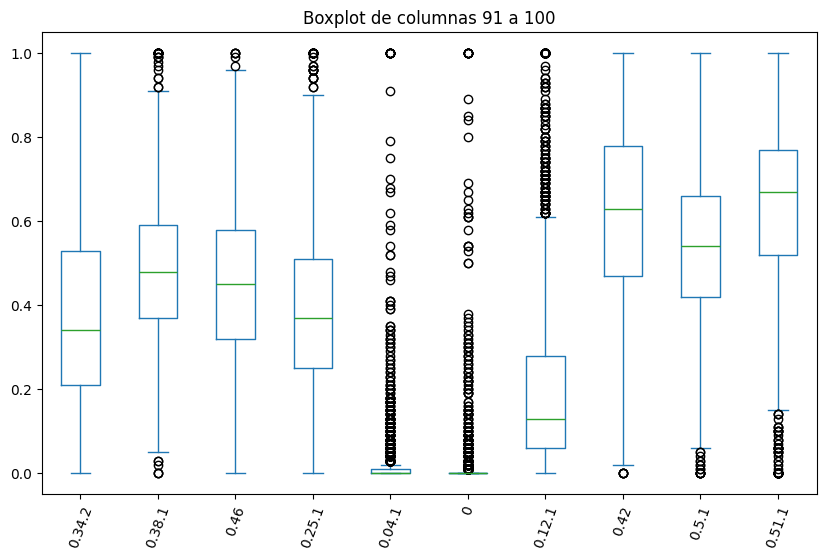

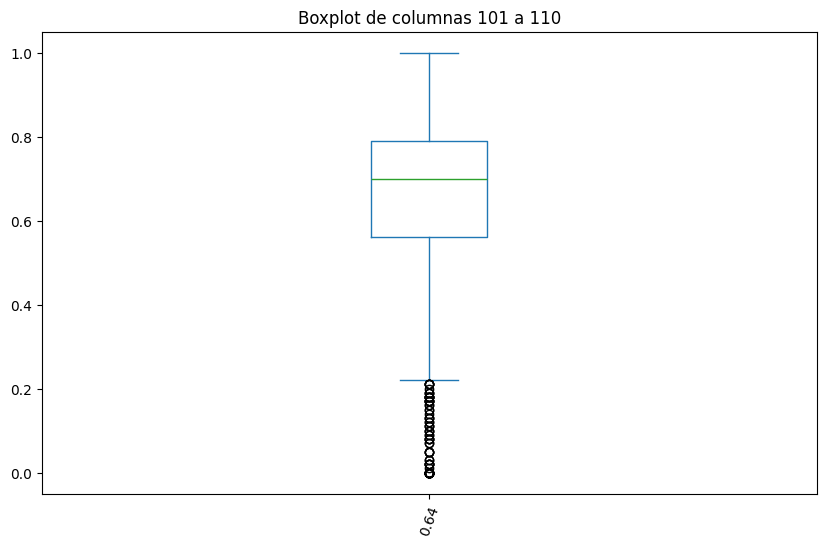

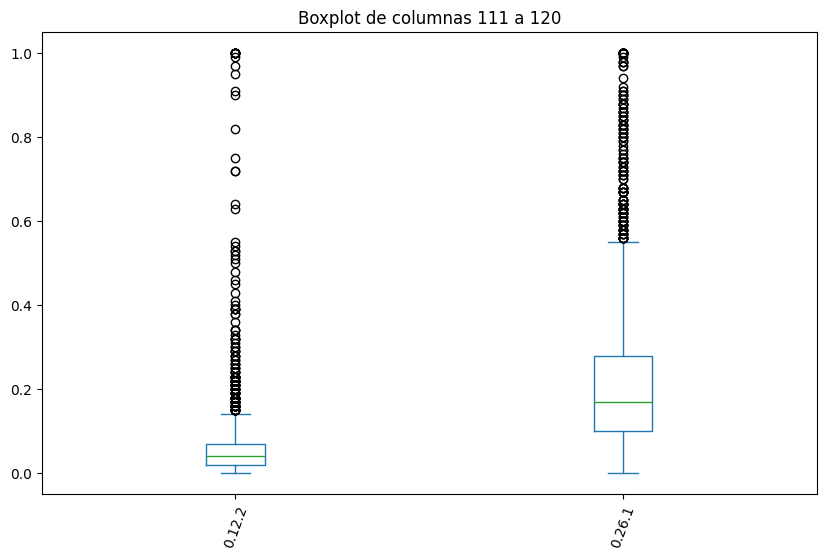

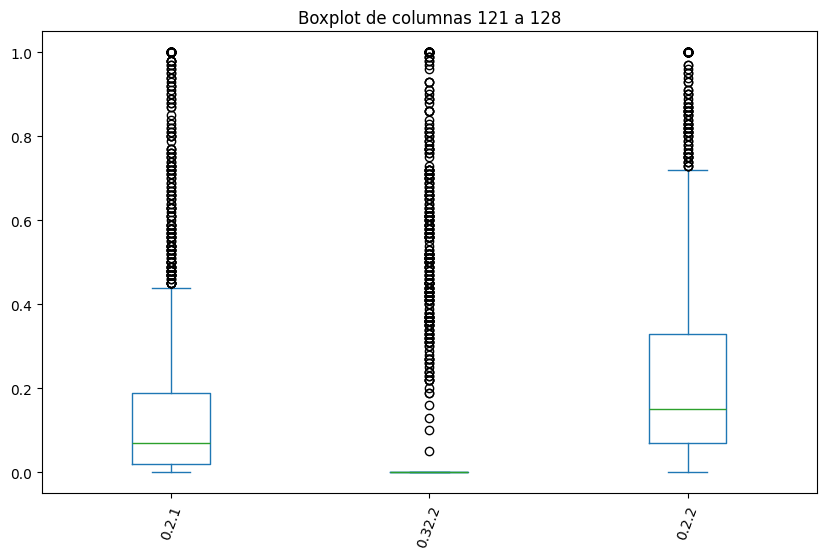

In [ ]:
import matplotlib.pyplot as plt

# Dividir en grupos de columnas
for i in range(0, dat.shape[1], 10):  # Incremento de 10 columnas
    dat.iloc[:, i:i+10].plot.box(figsize=(10, 6))
    plt.xticks(rotation=70)
    plt.title(f"Boxplot de columnas {i+1} a {min(i+10, dat.shape[1])}")
    plt.show()



# <font color="blue"> Conjunto de dígitos manuscritos</font>

In [ ]:
[digits,labs] = load_digits(return_X_y=True)
[N,d] = digits.shape # número de datos y dimensionalidad
print(N) #número de observaciones
print(d) #dimensionalidad

1797
64


In [ ]:
# Revisamos la primera observación
print(digits[0,:].shape)
digits[0,]

(64,)


array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

### Visualización de algunas observaciones

> Añadir blockquote



7
[[ 0.  0.  6. 15. 16.  3.  0.  0.]
 [ 0.  3. 16. 12. 15.  8.  0.  0.]
 [ 0.  0.  4.  0. 14.  6.  0.  0.]
 [ 0.  0.  0.  2. 16.  6.  2.  0.]
 [ 0.  0.  4. 14. 16. 16.  8.  0.]
 [ 0.  0. 15. 16.  7.  0.  0.  0.]
 [ 0.  0.  6. 16.  0.  0.  0.  0.]
 [ 0.  0.  7.  9.  0.  0.  0.  0.]]


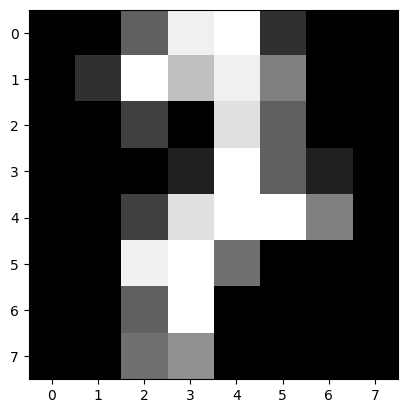

In [ ]:
#elige aleatoriamente algún dato y lo visualiza
n = randint(0,N)

plt.imshow(np.reshape(digits[n],(8,8)), cmap='gray')

print(labs[n])
print(np.reshape(digits[n],(8,8)))
plt.show()

### Descomposición en componentes principales

En este ejemplo nos apoyaremos de la librería $\texttt{sklearn}$ para realizar la reducción de la dimensionalidad de los datos mediante PCA.

**Para ejemplificar selecciona solamente a los datos correspondientes al 1 y al 9**

In [ ]:
d1 = 1
d2 = 9
ind_d1 = labs == d1
ind_d2 = labs == d2
dig1 = digits[ind_d1]
dig2 = digits[ind_d2]
X = np.vstack((dig1,dig2)) #en esta matriz están los datos seleccionados
lab1 = labs[ind_d1]
lab2 = labs[ind_d2]
nlabs = np.concatenate((lab1,lab2))

1
[[ 0.  0.  4. 16. 15.  7.  0.  0.]
 [ 0.  0.  6. 16. 16.  6.  0.  0.]
 [ 0.  0.  5. 16. 16.  4.  0.  0.]
 [ 0.  0.  7. 16. 15.  0.  0.  0.]
 [ 0.  0. 11. 16. 14.  0.  0.  0.]
 [ 0.  0.  6. 16. 14.  0.  0.  0.]
 [ 0.  0.  6. 16. 16.  5.  0.  0.]
 [ 0.  0.  2. 12. 16.  3.  0.  0.]]


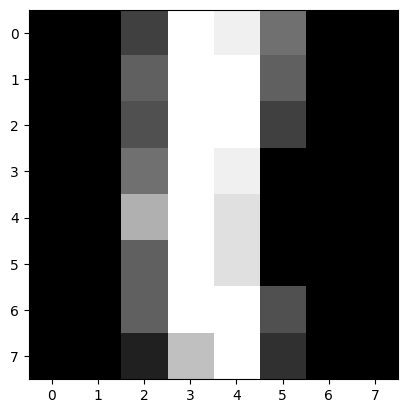

In [ ]:
#el primer subconjunto contiene 1's solamente
n1 = randint(0, dig1.shape[0])

print(lab1[n1])

plt.imshow(np.reshape(dig1[n1],(8,8)), cmap='gray')
print(np.reshape(dig1[n1],(8,8)))
plt.show()

9
[[ 0.  0.  0.  0. 12.  5.  0.  0.]
 [ 0.  0.  0.  2. 16. 12.  0.  0.]
 [ 0.  0.  1. 12. 16. 11.  0.  0.]
 [ 0.  2. 12. 16. 16. 10.  0.  0.]
 [ 0.  6. 11.  5. 15.  6.  0.  0.]
 [ 0.  0.  0.  1. 16.  9.  0.  0.]
 [ 0.  0.  0.  2. 16. 11.  0.  0.]
 [ 0.  0.  0.  3. 16.  8.  0.  0.]]


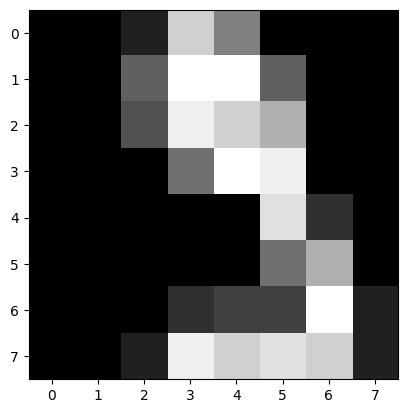

In [ ]:
#el segundo subconjunto contiene 9's solamente
n2 = randint(0, dig2.shape[0])

print(lab2[n2])

plt.imshow(np.reshape(dig2[n2],(8,8)), cmap='gray')
print(np.reshape(dig1[n2],(8,8)))
plt.show()

In [ ]:
pca = PCA(n_components=64) # usamos todas las dimensiones inicialmente para identificar el total de varianza proyectada
pca.fit(X)

PCA(n_components=64)

Identificamos cuántas componentes son necesarias.

In [ ]:
var_exp = pca.explained_variance_

np.round(np.cumsum(var_exp)/sum(var_exp)*100, 2)

#podemos proyectar en las primeras 8 o 9 dimensiones (aproximadamente la octava parte de las originales)

array([ 31.97,  47.8 ,  56.92,  62.57,  67.48,  71.45,  74.93,  77.88,
        80.63,  82.91,  84.78,  86.53,  87.82,  89.01,  90.1 ,  90.99,
        91.79,  92.56,  93.22,  93.84,  94.38,  94.89,  95.38,  95.81,
        96.18,  96.54,  96.89,  97.18,  97.46,  97.72,  97.98,  98.19,
        98.4 ,  98.59,  98.76,  98.92,  99.06,  99.19,  99.29,  99.4 ,
        99.49,  99.57,  99.65,  99.73,  99.79,  99.84,  99.9 ,  99.94,
        99.98,  99.99,  99.99, 100.  , 100.  , 100.  , 100.  , 100.  ,
       100.  , 100.  , 100.  , 100.  , 100.  , 100.  , 100.  , 100.  ])

## Proyecta los datos

Para esto, volvemos a evaluar las componentes principales para indicando el total de componentes a preservar:

In [ ]:
n_proy = 9
pca = PCA(n_components=n_proy) # proyectamos sobre el espacio definido por las primeras 9 componentes principales
pca.fit(X)

PCA(n_components=9)

In [ ]:
Xp = pca.transform(X) #usamos el comando "transform" para proyectar los datos al espacio de 9 dimensiones
Xp.shape

(362, 9)

In [ ]:
# compara con los datos originales
X.shape

(362, 64)

In [ ]:
# revisamos la proyección de la primera observación
Xp[0,]

array([24.30794939, -4.4892824 ,  2.05937115,  2.14595335, -2.26199199,
        1.46580342,  6.34540964, -4.63743224, -0.62483622])

observa que con esta técnica hemos reducido la dimensionalidad de los datos de 64 a 9 preservando una muy buena parte de la información del conjunto de datos originales.

### Visualización de las componentes principales

Podemos visualizar las primeras componentes principales (son vectores de 64 componentes al igual que las imágenes originales)

In [ ]:
pca.components_.shape

(9, 64)

**Cada componente principal es un vector de 64 componentes** que puede visualziarse como una imagen de $8\times 8$

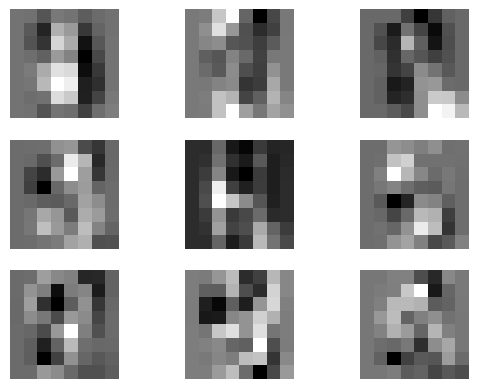

In [ ]:
for i in range(9):
  plt.subplot(3,3,i+1)
  plt.imshow(np.reshape(pca.components_[i,:],(8,8)), cmap='gray')
  plt.axis("off")

plt.show()

Y podemos usar esas 9 componentes para *recuperar* alguna imagen:

[-11.53381831 -26.10587236   8.89560578   4.77667773  -0.09995886
   9.54598707  -2.01020785  -6.11723176   1.74807451]


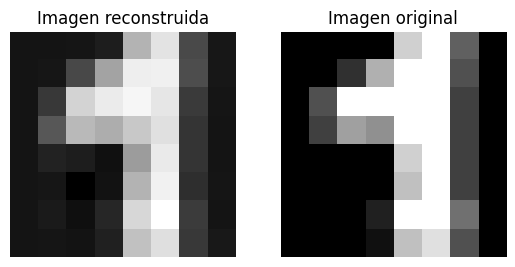

In [ ]:
#seleccionamos aleatoriamente alguna observación

n_ims = X.shape[0]      # total de imágenes
n = randint(0,n_ims-1)  # selecciona una imagen aleatoriamente

#reconstruimos la imagen multiplicando
#los valores proyectados del dato con
#las 9 componentes principales
print(Xp[n,])           # imagen proyectada a 9 componentes (cada valor nos indica en qué proporción se deben mezclar las componentes principales)

# recuperamos la imagen mediante la mezcla (combinación) de las componentes principales
dig_proy = np.dot(Xp[n, ], pca.components_) #se obtiene un vector de 64 componentes
# es necesario sumar las medias de las variables
dig_proy = dig_proy+pca.mean_

# Visualizamos los resultados
plt.subplot(1,2,1)
plt.imshow(np.reshape(dig_proy,(8,8)), cmap='gray')
plt.title("Imagen reconstruida")
plt.axis("off")

#comparamos con la imagen original
plt.subplot(1,2,2)
plt.title("Imagen original")
plt.imshow(np.reshape(X[n,],(8,8)), cmap='gray')
plt.axis("off")

plt.show()

## Proyección de los datos a un espacio bidimensional

Sólo para explorar la idea de la reducción de la dimensionalidad proyectaremos los dígitos a un espacio de dos dimensiones (se preserva alrededor del 50% de la información original)

In [ ]:
pca = PCA(n_components=2) # proyectamos sobre el espacio definido por las primeras 2 componentes principales
pca.fit(X)

PCA(n_components=2)

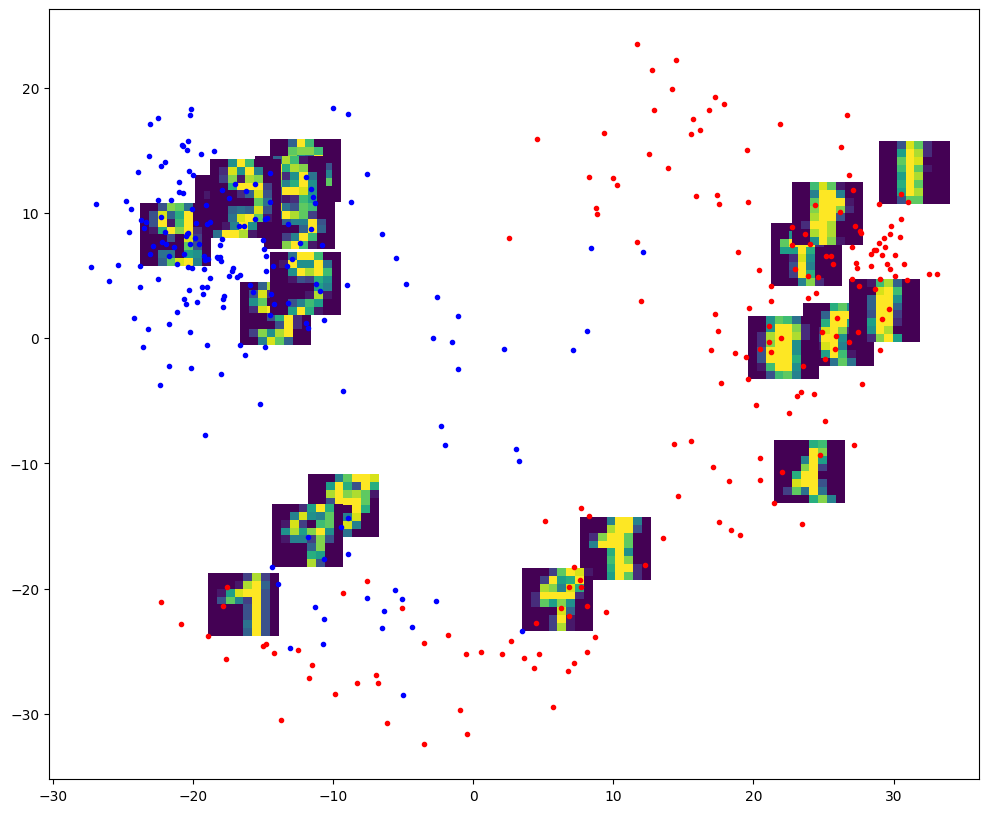

In [ ]:
dat_proy = pca.transform(X)

ind1 = nlabs == d1
ind2 = nlabs == d2

dig1_proy = dat_proy[ind1]
dig2_proy = dat_proy[ind2]

#grafica las proyecciones de cada dato
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111)

plt.plot(dig1_proy[:,0],dig1_proy[:,1],'r.')
plt.plot(dig2_proy[:,0],dig2_proy[:,1],'b.')

#selecciona aleatoriamente algunos datos y despliega sus imágenes

[N,d] = dat_proy.shape
for i in range(20):
    n = randint(0,N-1)
    x = dat_proy[n,0]
    y = dat_proy[n,1]
    bb = Bbox.from_bounds(x,y,5,5)
    bb2 = TransformedBbox(bb,ax.transData)
    bbox_image = BboxImage(bb2, norm = None, origin=None, clip_on=False)
    im = np.reshape(X[n,],(8,8))
    bbox_image.set_data(im)
    ax.add_artist(bbox_image)
plt.show()

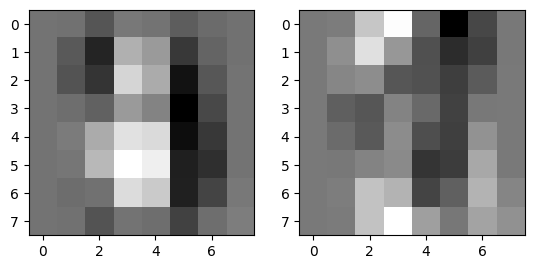

In [ ]:
#visualizamos las dos componentes principales
c = pca.components_

plt.subplot(121)
plt.imshow(np.reshape(c[0],(8,8)), cmap='gray')
plt.subplot(122)
plt.imshow(np.reshape(c[1],(8,8)), cmap='gray')
plt.show()

# <font color="red">Actividad</font>

En esta práctica vas a ajustar un par de modelos para clasificar las imágenes de unos y nueves que separamos en las celdas superiores. Para ambos modelos vas a ajustar un clasificador binario por XGBoost. Puedes basarte en la librería `sklearn`:

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html


* Construye el primer modelo entrenando con los datos originales. Evalúa la exactitud del modelo.
* Ajusta el segundo modelo a los datos proyectados con PCA, eligiendo el total de componentes de manera que se preserve el 80% de la varianza de los datos originales. Evalúa la exactitud del modelo.
* Ajusta el tercer modelo a los datos proyectados con PCA, a un espacio de dos dimensiones. Evalúa la exactitud del modelo.


**Nota:** Evalúa la exactitud de ambos modelos sobre los datos de entrenamiento, la idea no es generalizar los modelos sino verificar qué tanto se degrada la calidad predictiva al aplicar la transformación PCA.



# CELDA 1: CONFIGURACIÓN INICIAL Y CARGA DE DATOS


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_digits

# Cargar el conjunto de datos de dígitos
[digits, labs] = load_digits(return_X_y=True)

# Seleccionar sólo las clases 1 y 9
d1, d2 = 1, 9
ind_d1 = labs == d1
ind_d2 = labs == d2

# Crear subconjuntos de datos
dig1 = digits[ind_d1]
dig2 = digits[ind_d2]
X = np.vstack((dig1, dig2))  # Combinar dígitos 1 y 9
y = np.concatenate((labs[ind_d1], labs[ind_d2]))

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Dimensiones de los datos
print(f"Datos de entrenamiento: {X_train.shape}")
print(f"Datos de prueba: {X_test.shape}")


Datos de entrenamiento: (253, 64)
Datos de prueba: (109, 64)


#CELDA 2: Clasificador con los datos originales

In [ ]:
# Ajustar un modelo Gradient Boosting con los datos originales
clf_original = GradientBoostingClassifier(random_state=42)
clf_original.fit(X_train, y_train)

# Evaluar exactitud en los datos de entrenamiento y prueba
train_acc_orig = accuracy_score(y_train, clf_original.predict(X_train))
test_acc_orig = accuracy_score(y_test, clf_original.predict(X_test))

print(f"Exactitud en datos de entrenamiento (modelo original): {train_acc_orig:.2f}")
print(f"Exactitud en datos de prueba (modelo original): {test_acc_orig:.2f}")


Exactitud en datos de entrenamiento (modelo original): 1.00
Exactitud en datos de prueba (modelo original): 0.98


In [ ]:
X.shape

(362, 64)

In [ ]:
Y = nlabs == 1
Y

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

#Celda 3: Calcular la cantidad de componentes para preservar el 80% de la varianza

In [ ]:
# Calcular el PCA con todas las dimensiones
pca = PCA(n_components=64)
pca.fit(X_train)

# Calcular varianza acumulada
var_acum = np.cumsum(pca.explained_variance_ratio_)

# Encontrar el número de componentes necesarios para preservar el 80% de la varianza
n_components_80 = np.argmax(var_acum >= 0.80) + 1

print(f"Número de componentes para preservar el 80% de la varianza: {n_components_80}")


Número de componentes para preservar el 80% de la varianza: 9


#Celda 4: Modelo 2 - Clasificador con PCA (80% varianza)



In [ ]:
# Proyectar los datos al espacio PCA con n_components_80
pca_80 = PCA(n_components=n_components_80)
X_train_pca_80 = pca_80.fit_transform(X_train)
X_test_pca_80 = pca_80.transform(X_test)

# Ajustar un modelo Gradient Boosting con los datos proyectados
clf_pca_80 = GradientBoostingClassifier(random_state=42)
clf_pca_80.fit(X_train_pca_80, y_train)

# Evaluar exactitud en los datos de entrenamiento y prueba
train_acc_pca_80 = accuracy_score(y_train, clf_pca_80.predict(X_train_pca_80))
test_acc_pca_80 = accuracy_score(y_test, clf_pca_80.predict(X_test_pca_80))

print(f"Exactitud en datos de entrenamiento (PCA 80%): {train_acc_pca_80:.2f}")
print(f"Exactitud en datos de prueba (PCA 80%): {test_acc_pca_80:.2f}")


Exactitud en datos de entrenamiento (PCA 80%): 1.00
Exactitud en datos de prueba (PCA 80%): 0.97


#Celda 5: Modelo 3 - Clasificador con PCA (2 dimensiones)

*   Elemento de lista
*   Elemento de lista




In [ ]:
# Proyectar los datos al espacio PCA con 2 dimensiones
pca_2d = PCA(n_components=2)
X_train_pca_2d = pca_2d.fit_transform(X_train)
X_test_pca_2d = pca_2d.transform(X_test)

# Ajustar un modelo Gradient Boosting con los datos proyectados
clf_pca_2d = GradientBoostingClassifier(random_state=42)
clf_pca_2d.fit(X_train_pca_2d, y_train)

# Evaluar exactitud en los datos de entrenamiento y prueba
train_acc_pca_2d = accuracy_score(y_train, clf_pca_2d.predict(X_train_pca_2d))
test_acc_pca_2d = accuracy_score(y_test, clf_pca_2d.predict(X_test_pca_2d))

print(f"Exactitud en datos de entrenamiento (PCA 2D): {train_acc_pca_2d:.2f}")
print(f"Exactitud en datos de prueba (PCA 2D): {test_acc_pca_2d:.2f}")


Exactitud en datos de entrenamiento (PCA 2D): 1.00
Exactitud en datos de prueba (PCA 2D): 0.93


#CELDA 6 : RESUMEN DLE REUSLTADO

1.   Elemento de lista
2.   Elemento de lista



In [ ]:
# Mostrar las métricas de evaluación de los tres modelos
print("Resumen de exactitudes:")
print(f"Modelo original - Entrenamiento: {train_acc_orig:.2f}, Prueba: {test_acc_orig:.2f}")
print(f"Modelo PCA 80% - Entrenamiento: {train_acc_pca_80:.2f}, Prueba: {test_acc_pca_80:.2f}")
print(f"Modelo PCA 2D - Entrenamiento: {train_acc_pca_2d:.2f}, Prueba: {test_acc_pca_2d:.2f}")


Resumen de exactitudes:
Modelo original - Entrenamiento: 1.00, Prueba: 0.98
Modelo PCA 80% - Entrenamiento: 1.00, Prueba: 0.97
Modelo PCA 2D - Entrenamiento: 1.00, Prueba: 0.93


# <font color="red">Modelo basado en las 64 componentes originales</font>#

1.   Elemento de lista
2.   Elemento de lista



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gbc64 = GradientBoostingClassifier(n_estimators=25, max_depth=3)
# Define Y before fitting the model
# Assuming Y should represent if the digit is 1 (True) or 9 (False)
Y = nlabs == 1
gbc64.fit(X,Y)

GradientBoostingClassifier(n_estimators=25)

In [ ]:
gbc64.score(X,Y)

1.0

In [ ]:
yp = gbc64.predict(X)
pd.DataFrame({"yp":yp,"Y":Y})

,yp,Y
0,True,True
1,True,True
2,True,True
3,True,True
4,True,True
...,...,...
357,False,False
358,False,False
359,False,False
360,False,False


from matplotlib import pyplot as plt
import seaborn as sns
_df_0.groupby('yp').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
_df_1.groupby('Y').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
plt.subplots(figsize=(8, 8))
df_2dhist = pd.DataFrame({
    x_label: grp['Y'].value_counts()
    for x_label, grp in _df_2.groupby('yp')
})
sns.heatmap(df_2dhist, cmap='viridis')
plt.xlabel('yp')
_ = plt.ylabel('Y')

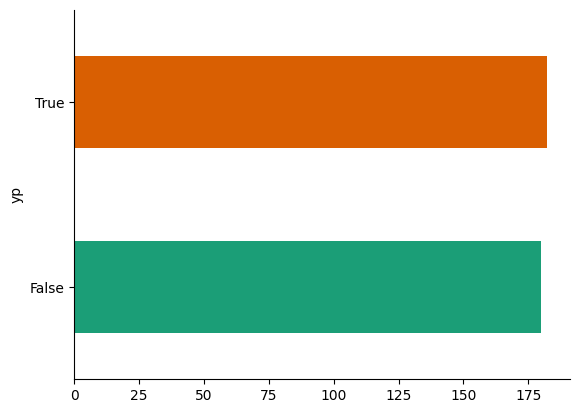

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
_df_0.groupby('yp').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

# Modelo basado en las 9 componentes principales (proyectadas)

Proyección a 9 componentes principales con PCA:

pca = PCA(n_components=9): Se configura PCA para reducir los datos a 9 dimensiones.
X_pca = pca.fit_transform(X): Se proyectan los datos originales (
𝑋
X) al espacio de 9 componentes principales.
Entrenamiento del modelo:

GradientBoostingClassifier: Entrena un modelo basado en Gradient Boosting utilizando las 9 componentes proyectadas como entrada (
𝑋
𝑃
𝐶
𝐴
X
PCA
​
 ).
Evaluación del modelo:

gbc9.score(X_pca, Y): Se calcula la exactitud del modelo utilizando los datos proyectados (
𝑋
𝑃
𝐶
𝐴
X
PCA
​
 ) y las etiquetas (
𝑌
Y).
Predicciones y comparación:

yp_pca9 = gbc9.predict(X_pca): Se generan las predicciones para las 9 componentes principales.
pd.DataFrame({"yp_pca9": yp_pca9, "Y": Y}): Se crea un DataFrame para comparar las predicciones (
𝑌
^
Y
^
 ) con las etiquetas reales (
𝑌
Y).
Visualización:

Se genera un gráfico de barras horizontales para mostrar la distribución de las predicciones entre True (1) y False (9).

Exactitud del modelo basado en 9 componentes principales: 1.00

Comparación de predicciones y etiquetas reales:
   yp_pca9     Y
0     True  True
1     True  True
2     True  True
3     True  True
4     True  True


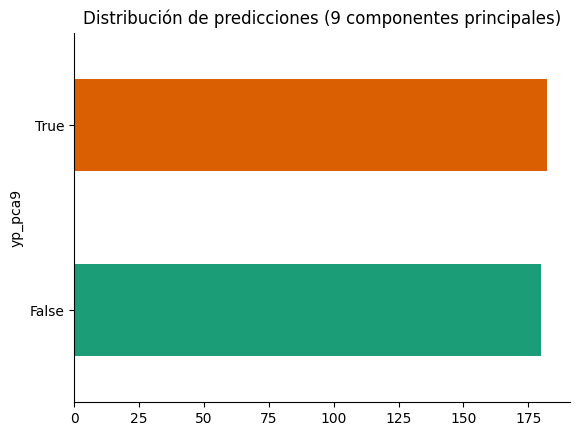

In [ ]:

# Reducción de dimensionalidad a 9 componentes principales con PCA
pca = PCA(n_components=9)
X_pca = pca.fit_transform(X)

# Ajustar un modelo Gradient Boosting con las 9 componentes principales
gbc9 = GradientBoostingClassifier(n_estimators=25, max_depth=3)
gbc9.fit(X_pca, Y)

# Evaluar el modelo
train_accuracy_pca9 = gbc9.score(X_pca, Y)
print(f"Exactitud del modelo basado en 9 componentes principales: {train_accuracy_pca9:.2f}")

# Predicciones del modelo
yp_pca9 = gbc9.predict(X_pca)

# Comparar las predicciones con las etiquetas reales
df_comparison_pca9 = pd.DataFrame({"yp_pca9": yp_pca9, "Y": Y})
print("\nComparación de predicciones y etiquetas reales:")
print(df_comparison_pca9.head())

# Visualización de los resultados agrupados por predicciones
df_comparison_pca9.groupby('yp_pca9').size().plot(kind='barh', color=sns.color_palette('Dark2'))
plt.title("Distribución de predicciones (9 componentes principales)")
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()


# Modelo basado en dos componentes

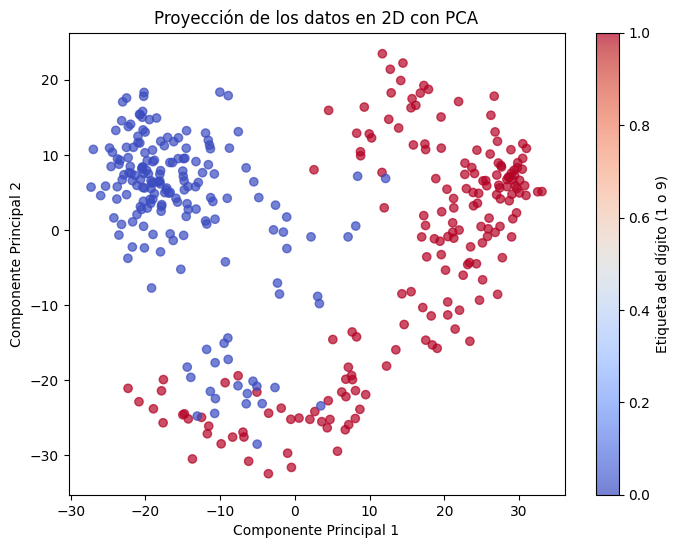

In [ ]:

# Project data onto 2 principal components using PCA
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X)

# Now you can visualize the separation of the data in 2D
plt.figure(figsize=(8,6))
plt.scatter(X_pca_2d[:,0], X_pca_2d[:,1], c=Y, cmap='coolwarm', alpha=0.7)
plt.colorbar(label="Etiqueta del dígito (1 o 9)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.title("Proyección de los datos en 2D con PCA")
plt.show()